# Part 1 — evaluation, complementary blends and J

This notebook recomputes the current winner comparison from retained held-out predictions on **all 84 cases**: 40 Train157 folds, 40 Pooled235 folds, original validation and three chronological windows. It does not train those components again. Repeated-fold evidence is development evidence, not independent significance tests.
Run with Python 3.12 and the pinned `requirements.txt` beside this notebook. In Colab, extract the complete ZIP, change into `midterm/part1`, and install those dependencies before running. The supplied inputs and selected evidence are included; no Git checkout, private path, external trial data, or model cache is required. Notebook 05 contains the complete packaged Python source.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

# Works from the extracted part1 directory or from the repository root.
options = [Path.cwd(), Path.cwd() / "submission/midterm/part1", Path.cwd() / "midterm/part1"]
HOME = next((p for p in options if (p / "resources/handin.py").is_file()), None)
if HOME is None:
    raise RuntimeError("Extract the complete Part 1 ZIP and open this notebook beside its resources folder.")
RES = HOME / "resources"
OUT = HOME / "generated"
OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(RES))
import handin as h
P1, LABELS, EMB = h.P1, h.LABELS, h.EMB
# Stable numerical behavior; release automatically when the kernel exits.
thread_limit = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
display(h.verify_resources())

{'files': 763, 'hashes_match': True, 'external_checkout_required': False}

## Complete repeats, paired comparisons and chronology

Each grouped repeat contains every gold row exactly once. Compute sample-wise F1 over the complete out-of-fold predictions, then average the eight repeats; do not take an unweighted mean of fold F1 values. Chronology pools 98 predictions across the three fixed earlier-to-later windows. The original validation retains the original no-outer-purge boundary; grouped CV purges matching embedding groups from masked fitting rows.

In [2]:
repeat = h.winner_repeats()
summary = repeat.groupby(["pool","recipe"]).agg(mean_sample_f1=("sample_f1","mean"), population_sd=("sample_f1",lambda v:np.std(v,ddof=0)), mean_macro_f1=("macro_f1","mean")).reset_index()
display(summary)
repeat.to_csv(OUT / "winner_repeat_scores.csv",index=False)
summary.to_csv(OUT / "winner_benchmark.csv",index=False)
for pool, expected in [("train",(5,1,2)),("pooled",(4,1,3))]:
    paired=repeat[repeat.pool==pool].pivot(index="seed",columns="recipe",values="sample_f1")
    delta=paired.winner-paired.anchored
    counts=(int((delta>1e-12).sum()),int((abs(delta)<=1e-12).sum()),int((delta<-1e-12).sum()))
    assert counts==expected
    print(pool,"wins/ties/losses:",counts,"mean delta:",delta.mean())

,pool,recipe,mean_sample_f1,population_sd,mean_macro_f1
0,chronology98,anchored,0.884354,0.000000,0.841633
1,chronology98,cand2,0.863946,0.000000,0.823683
2,chronology98,winner,0.887755,0.000000,0.842570
3,pooled,anchored,0.921365,0.006695,0.850426
4,pooled,cand2,0.903599,0.007480,0.831572
5,pooled,winner,0.921631,0.005891,0.851670
6,train,anchored,0.932059,0.006369,0.882677
7,train,cand2,0.923301,0.010901,0.893773
8,train,winner,0.935244,0.006457,0.895350
9,validation,anchored,0.891026,0.000000,0.765430


train wins/ties/losses: (5, 1, 2) mean delta: 0.0031847133757962054
pooled wins/ties/losses: (4, 1, 3) mean delta: 0.00026595744680853184


The winner did not meet the original five-wins-in-both-pools rule. An explicitly authorized exploratory submission subsequently scored .89935. We preserve both facts. Its validation predictions match anchored; Pooled235 improvement is small. The prior 75/25 anchored/LDA blend remains the stronger Pooled235 average.

,model,train,pooled,validation,chronology98,kaggle
0,Anchored80/Cand2_20 (winner),0.935244,0.921631,0.891026,0.887755,0.89935
1,Anchored75/LDA25,0.932059,0.923404,0.891026,0.884354,0.89850
2,Anchored,0.932059,0.921365,0.891026,0.884354,0.89636
3,80% prior 75/25 + 20% PySR,0.927548,0.919770,0.884615,0.877551,0.89423
4,LDA ensemble 70/15/15,0.931794,0.921631,0.905983,0.877551,0.89401
5,Anchored80/diverse-kernel20,0.933386,0.920922,0.886752,0.870748,0.89316
6,Cand2 strict five-seed,0.923301,0.903599,0.871795,0.863946,0.89102
7,Log-odds anchored80/Cand2_20,0.935775,0.922429,0.891026,0.887755,0.88888
8,Partial-Other80/Cand2_20,0.920382,0.914982,0.891026,0.901020,0.86645


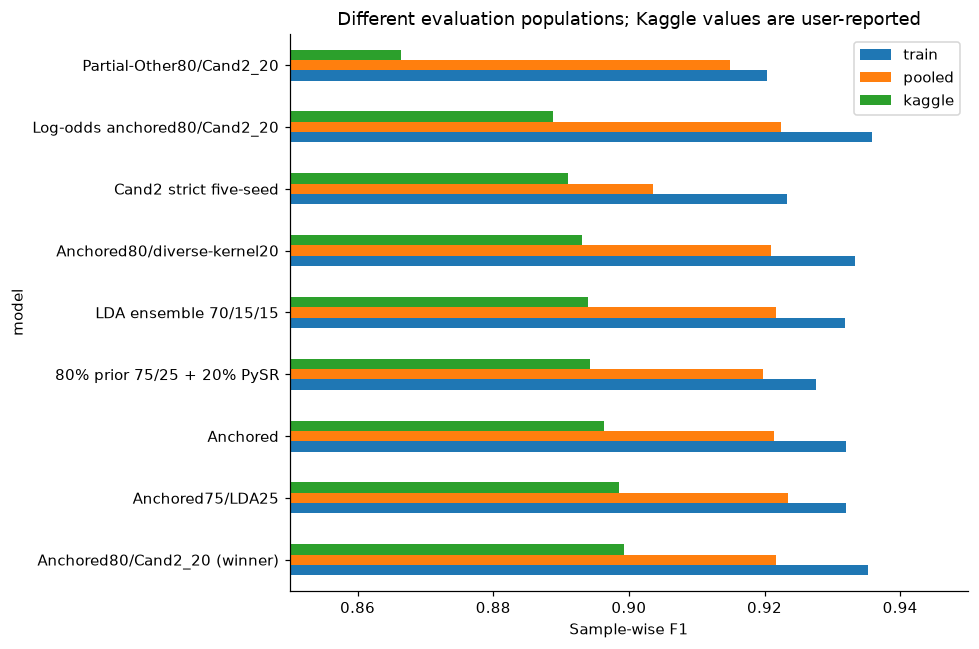

In [3]:
comparison = pd.read_csv(P1 / "reporting/benchmark_comparison.csv")
for recipe, model in [("winner","Anchored80/Cand2_20 (winner)"),("anchored","Anchored"),("cand2","Cand2 strict five-seed")]:
    current=comparison.set_index("model").loc[model]
    actual=summary[summary.recipe==recipe].set_index("pool")
    np.testing.assert_allclose(actual.loc[["train","pooled","validation","chronology98"],"mean_sample_f1"], current[["train","pooled","validation","chronology98"]].to_numpy(float),atol=1e-12,rtol=0)
display(comparison[["model","train","pooled","validation","chronology98","kaggle"]])
ax=comparison.set_index("model")[["train","pooled","kaggle"]].plot.barh(figsize=(9,6),xlim=(.85,.95),title="Different evaluation populations; Kaggle values are user-reported")
ax.set_xlabel("Sample-wise F1");plt.tight_layout();plt.savefig(OUT / "model_comparison.png");plt.show()

## What J measures, and what its ordering means

J is `(A+B)/2`: A is the original ten-repeat ordinary (ungrouped) CV score over 235 labels; B is the mean of three original chronological cuts. B retains all originally masked training years. Our current chronology uses earlier eligible rows and duplicate-group purges. These are different stress tests.

For each pair with unequal reported Kaggle scores, a metric orders the pair correctly when it assigns the higher local value to the higher Kaggle result. Pairs share models and are not independent observations. Exclude original Ani when asking about matched submitted recipes because its local adaptation differs from the historical scored artifact. The original six-recipe and later expanded panels have different denominators.

In [4]:
from itertools import combinations
panel=pd.read_csv(P1 / "experiments/cand2_followup_v1/results/expanded_panel.csv")
matched=panel[panel.model!="original_ani"]
rows=[]
for metric in ["dylan_J","grouped_train","grouped_pooled"]:
    correct=wrong=tied=0
    for (_,a),(_,b) in combinations(matched.iterrows(),2):
        kg=a.kaggle-b.kaggle
        if abs(kg)<1e-12:continue
        local=a[metric]-b[metric]
        if abs(local)<1e-12:tied+=1
        elif kg*local>0:correct+=1
        else:wrong+=1
    rows.append(dict(metric=metric,correct=correct,wrong=wrong,tied=tied,total=correct+wrong+tied))
rank=pd.DataFrame(rows)
assert rank.correct.tolist()==[10,14,13] and rank.total.tolist()==[14,14,14]
display(rank)
rank.to_csv(OUT / "J_pair_ordering.csv",index=False)
display(panel[panel.model.isin(["anchored","cand2_inductive5"])])

,metric,correct,wrong,tied,total
0,dylan_J,10,4,0,14
1,grouped_train,14,0,0,14
2,grouped_pooled,13,1,0,14


,model,kaggle,dylan_A,dylan_B,dylan_B2005,dylan_J,validation,grouped_train,grouped_pooled,chronology98,strict_B,aligned_J,current_J_diagnostic
5,anchored,0.89636,0.92461,0.846855,0.840136,0.885733,0.891026,0.932059,0.921365,0.884354,0.85332,0.887343,0.902859
6,cand2_inductive5,0.89102,NaN,NaN,NaN,0.896171,NaN,0.923301,0.903599,NaN,NaN,NaN,NaN


## Interpretation

The exact strict Cand2 recipe scored lower than anchored on Kaggle while J preferred it. Its small fixed contribution still helped the arithmetic blend. This supports testing complementary combinations; it does not validate J as a universal ranker or prove that decorrelation alone improves performance. Local improvements from log-odds pooling failed on Kaggle, as notebook 04 shows. No replacement J formula was fitted to these outcomes.